<a href="https://colab.research.google.com/github/AliPatrick71/AI-Science-Engineering/blob/main/week3_bitcoin_ml_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3 Assignment: End-to-End Machine Learning Workflow
## AI for Science and Engineering

### 1. Project problem and intended AI/ML outcome

My project investigates whether machine learning can predict the direction of Bitcoin's price over the next 15 minutes. The intended outcome is a model that uses recent market information to classify whether the next 15-minute closing price will be higher or lower than the current closing price. The model's performance would later be compared with a simple baseline, while recognizing that predictions are uncertain and do not guarantee profitable trades.

### 2. Data needed

I need time-stamped Bitcoin market data containing:
- Open, high, low, and close prices (OHLC).
- Trading volume.
- Recent price changes and technical indicators, such as moving averages and the Relative Strength Index (RSI).
- A future price movement label that can be used as the target.

For this introductory assignment, I will retrieve BTC-USD 15-minute data from Yahoo Finance using the `yfinance` Python library. Availability and historical coverage can change, so the notebook checks what data is returned. The downloaded sample is suitable for demonstrating the workflow; a larger, carefully sourced dataset would be needed for robust research.


### 3. Import the dataset and inspect it

The following code downloads Bitcoin market data, shows the first few rows, and reports the dataset's size and columns. If `yfinance` cannot retrieve data in your environment, download a Bitcoin OHLCV CSV dataset from a source such as [Kaggle](https://www.kaggle.com/datasets) and load it with `pandas.read_csv()` instead.


In [5]:
# Install the data-download library in Colab if it is not already installed.
%pip -q install yfinance


In [6]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Download recent Bitcoin-USD market data at 15-minute intervals.
# Yahoo Finance generally limits how far back intraday data can be retrieved.
ticker = "BTC-USD"
data = yf.download(ticker, period="60d", interval="15m", auto_adjust=False, progress=False)

if data.empty:
    raise ValueError(
        "No data was returned. Try again later or load a Bitcoin OHLCV CSV file "
        "using pd.read_csv('your_file.csv')."
    )

# Flatten column labels if the data provider returns a MultiIndex.
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data.reset_index()
print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())
display(data.head(10))


Dataset shape: (5722, 7)
Columns: ['Datetime', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


Price,Datetime,Adj Close,Close,High,Low,Open,Volume
0,2026-08-29 00:00:00+00:00,77812.476562,77812.476562,77870.937500,77781.210938,77839.187500,120557568
1,2026-08-29 00:15:00+00:00,77901.671875,77901.671875,77950.312500,77808.687500,77812.476562,120414208
2,2026-08-29 00:30:00+00:00,77784.750000,77784.750000,77897.703125,77767.648438,77897.703125,88735744
3,2026-08-29 00:45:00+00:00,77734.476562,77734.476562,77819.398438,77715.742188,77784.742188,0
4,2026-08-29 01:00:00+00:00,77632.781250,77632.781250,77724.992188,77631.023438,77717.867188,0
5,2026-08-29 01:15:00+00:00,77795.976562,77795.976562,77795.976562,77639.257812,77639.257812,0
6,2026-08-29 01:30:00+00:00,77827.476562,77827.476562,77832.062500,77761.492188,77788.460938,0
7,2026-08-29 01:45:00+00:00,77792.039062,77792.039062,77854.148438,77750.828125,77815.281250,0
8,2026-08-29 02:00:00+00:00,77738.460938,77738.460938,77825.976562,77735.203125,77792.039062,0
9,2026-08-29 02:15:00+00:00,77633.296875,77633.296875,77748.898438,77578.062500,77738.468750,0


### 4. Identify potential features and target

**Potential input features (X):**
- Open, high, low, and close prices for the current 15-minute interval.
- Trading volume.
- Recent percentage returns.
- Moving averages and RSI, calculated only from current and past data.

**Target (y):** a binary label indicating whether the next interval's closing price is higher than the current interval's closing price:
- `1` = price rises over the next 15 minutes.
- `0` = price does not rise (it is unchanged or falls).

The target is created by shifting the closing price one row into the future. The future price is used only to create the target, not as an input feature. This helps prevent information from the future leaking into the model's inputs.


In [7]:
# Standardize column names for easier use.
data.columns = [str(c).lower().replace(" ", "_") for c in data.columns]

# Identify the close and volume columns returned by Yahoo Finance.
required = {"close", "high", "low", "open", "volume"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Expected market-data columns are missing: {missing}")

# Create features from current and historical observations only.
data["return_1"] = data["close"].pct_change()
data["return_4"] = data["close"].pct_change(4)
data["sma_4"] = data["close"].rolling(4).mean()
data["sma_16"] = data["close"].rolling(16).mean()

# Calculate a simple 14-period RSI using past price changes.
delta = data["close"].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
relative_strength = gain / loss.replace(0, float("nan"))
data["rsi_14"] = 100 - (100 / (1 + relative_strength))

# Target: will the next 15-minute close be higher than the current close?
data["next_close"] = data["close"].shift(-1)
data["target_up"] = (data["next_close"] > data["close"]).astype(int)

feature_columns = [
    "open", "high", "low", "close", "volume",
    "return_1", "return_4", "sma_4", "sma_16", "rsi_14"
]

# Remove rows with missing values caused by rolling calculations.
# Remove the final row because its next-period close is unknown.
model_data = data.dropna(subset=feature_columns).iloc[:-1].copy()

X = model_data[feature_columns]
y = model_data["target_up"]

print("Feature matrix shape:", X.shape)
print("Target distribution (0 = not up, 1 = up):")
display(y.value_counts().rename_axis("target").to_frame("count"))
display(model_data[feature_columns + ["target_up"]].head())


Feature matrix shape: (5706, 10)
Target distribution (0 = not up, 1 = up):


,count
target,
0,2876
1,2830


,open,high,low,close,volume,return_1,return_4,sma_4,sma_16,rsi_14,target_up
15,77610.062500,77610.062500,77501.039062,77501.046875,986013696,-0.001405,-0.002151,77618.513672,77712.940430,28.704319,1
16,77505.703125,77592.296875,77504.000000,77580.492188,89866240,0.001025,-0.001231,77594.601562,77698.441406,38.691902,1
17,77580.476562,77619.671875,77575.812500,77608.539062,0,0.000362,-0.001007,77575.037109,77680.120605,42.851948,1
18,77608.539062,77640.039062,77578.921875,77613.796875,113709056,0.000068,0.000048,77575.968750,77669.436035,48.790009,1
19,77613.812500,77674.929688,77600.843750,77640.421875,4974592,0.000343,0.001798,77610.812500,77663.557617,37.995731,1


### 5. Proposed machine-learning workflow

```text
Define the research question
          |
          v
Collect Bitcoin 15-minute OHLCV data
          |
          v
Inspect, clean, and prepare the data
          |
          v
Create historical features and next-period target
          |
          v
Split chronologically into training, validation, and test sets
          |
          v
Train a baseline and candidate ML model
          |
          v
Evaluate on unseen data (accuracy, precision, recall)
          |
          v
Interpret results, limitations, and possible data leakage
          |
          v
Document code, data source, and experiment for reproducibility
```

**Explanation:** First, define the prediction task and obtain time-stamped data. Next, inspect and clean the observations, then engineer features using only information that would have been available at prediction time. Split the data in chronological order rather than randomly, because future observations must not influence training. Train a simple baseline and a machine-learning model, tune choices using validation data, and reserve the test set for final evaluation. Finally, interpret the results and document the process so it can be repeated. This assignment focuses on framing and data preparation; it does not claim that a model is already accurate or profitable.


### 6. Visualize a small part of the dataset

The chart below gives a quick view of the downloaded closing prices. It is exploratory and does not itself demonstrate predictive performance.


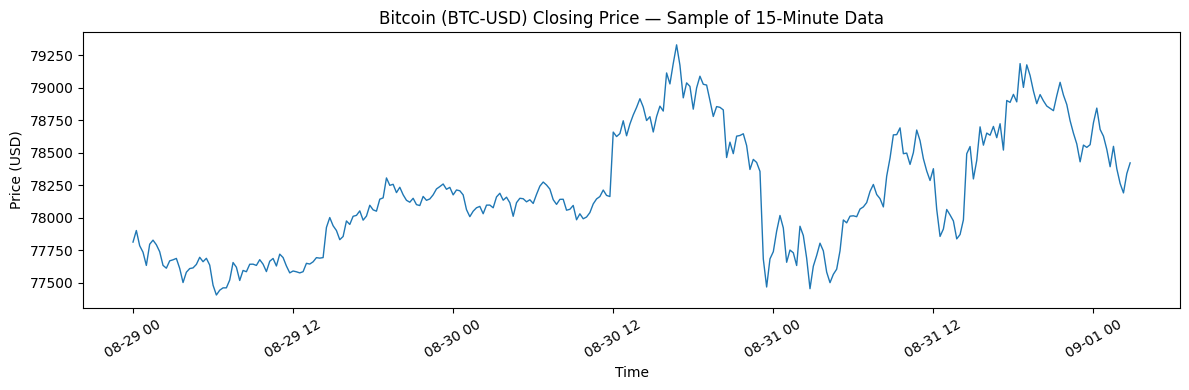

In [8]:
# Plot a sample of the closing-price series.
plt.figure(figsize=(12, 4))
plt.plot(data.iloc[:300]["datetime"] if "datetime" in data.columns else data.iloc[:300, 0],
         data.iloc[:300]["close"], linewidth=1)
plt.title("Bitcoin (BTC-USD) Closing Price — Sample of 15-Minute Data")
plt.xlabel("Time")
plt.ylabel("Price (USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### 7. Reproducibility and limitations

- The notebook downloads data when it is run, so the exact rows may change over time.
- Record the download date and keep a copy of the dataset if the course requires exact reproducibility.
- Market data can contain gaps, and intraday data availability may be limited.
- A high classification score does not automatically mean a profitable strategy. Transaction fees, spreads, slippage, and risk must be considered.
- Any later model evaluation should use chronological train/validation/test splits and compare against a baseline.

### Conclusion

This notebook defines a specific machine-learning task, identifies the required data, imports and inspects Bitcoin market data, identifies potential features and a target, and outlines an end-to-end ML workflow. The next step would be to create a chronological split and train a baseline model before evaluating more advanced models.
